# Ant Colony Optimization for Vehicle Routing with Time Windows
**Project:** ADEME call, CesiCDP delivery route optimization

**The problem in one sentence.** Trucks leave one depot, deliver to many customers, and come back. Each truck has a limited capacity, each customer must be served inside a time window, and we want the **shortest total distance**.

**What this notebook does, in order:**

| Section | Content |
|---|---|
| **1. The Ant Colony Algorithm** | what it is, how it works, and its code |
| **2. Parameters** | every setting of the notebook, in one place |
| **3. Example on one Solomon instance** | import one instance, draw its graph, solve it, draw the solution, check it |
| **4. Importing the instances** | Solomon (100 customers), Gehring & Homberger (200 to 800+), NetworkX graphs (500 to 10 000 nodes) |
| **5. Running the Ant Colony Algorithm** | on every imported instance |
| **6. Calculating the gap** | how far each result is from the best known solution |
| **7. Reading the results** | what to look at and what to be careful about |

**How to run.** Run sections 1 and 2 first. Then run the sections you need in order. Every result is saved in the `results/` folder and every chart in the `images/` folder. A long run that is stopped can be restarted: finished runs are not computed again.

**Data.** This notebook uses **real benchmark files only** (no fake data). If a file cannot be found or downloaded, it is skipped and a message tells you where to put it.

---
# 1. The Ant Colony Algorithm

## 1.1 The problem we solve
We have a **depot** (node 0) and $n$ **customers** (nodes 1 to $n$). Each customer $i$ has:
- a **demand** $d_i$ (how much it orders),
- a **time window** $[a_i, b_i]$ (service must start between $a_i$ and $b_i$),
- a **service time** $s_i$ (how long the delivery takes).

Each truck carries at most $Q$, there are at most $k$ trucks, and the depot closes at time $b_0$. Travelling from $i$ to $j$ costs $c_{ij}$ (the straight-line distance, also equal to the travel time).

This is the ILP of the previous notebook:
- **Objective:** minimise the total distance $\sum c_{ij}\,x_{ij}$, where $x_{ij}=1$ if a truck drives from $i$ to $j$.
- **Constraints (1)-(2):** every customer is entered once and left once.
- **Constraint (3):** at most $k$ trucks, all leaving from and returning to the depot.
- **Constraints (4)-(5):** the load $u_i$ grows along each route and never exceeds $Q$.
- **Constraints (6)-(8):** the clock $t_i$ grows along each route, service starts inside $[a_i, b_i]$, and the truck is back before the depot closes.
- **Constraint (9):** $x_{ij}$ is 0 or 1.

Solving this ILP exactly is only possible for a few dozen customers. For hundreds or thousands we need a **metaheuristic**: a method that finds very good solutions quickly, without proof that they are the best.

## 1.2 The idea: how real ants find short paths
Real ants leave a chemical trail, **pheromone**, when they walk. Other ants tend to follow strong trails. A short path gets walked more often per hour, so it collects more pheromone, so it attracts more ants. At the same time, pheromone **evaporates**, so trails that are not used fade away. After a while, the colony follows the shortest path, even though no single ant knows it.

The **Ant Colony Optimization (ACO)** algorithm copies this with artificial ants:
- an artificial ant **builds a complete solution** (all the truck routes), one customer at a time;
- good solutions leave **pheromone** on the roads they used;
- the next ants are attracted by pheromone but still explore;
- pheromone **evaporates** a little at each round.

Ant colonies are a recognised method for this exact problem: the multiple ant colony system of Gambardella, Taillard and Agazzi (MACS-VRPTW, 1999) still holds the best known solution of one Solomon instance (R112).

## 1.3 How the algorithm works, step by step
We use the **Max-Min Ant System (MMAS)**, a robust version of ACO.

**Step 1. Each ant builds a solution.** The ant starts at the depot with an empty truck at time 0. At each step it looks at the customers it can still serve (enough capacity left, time window still reachable, and enough time to return to the depot). Among those, it chooses customer $j$ with probability

$$p_{ij} = \frac{\tau_{ij}^{\alpha}\;\eta_{ij}^{\beta}}{\sum_{l \in F}\tau_{il}^{\alpha}\;\eta_{il}^{\beta}}$$

- $\tau_{ij}$ is the **pheromone** on the road $i \to j$ (the colony's memory),
- $\eta_{ij}$ is the **visibility** (how attractive $j$ looks right now): it is high when $j$ is close, needs little waiting, and has a window that closes soon:
$$\eta_{ij} = \frac{1}{0.4\,c_{ij} + 0.4\,(\text{waiting + travel time}) + 0.2\,(b_j - \text{current time})}$$
- $\alpha$ and $\beta$ set how much the ant trusts the memory and the visibility.

With probability $q_0$ the ant simply takes the best customer (exploitation); otherwise it draws one at random with the probabilities above (exploration). When no customer is possible, the truck returns to the depot and a **new truck** starts.

**Step 2. Clean-up (local search).** The best solution of the round is improved by two simple moves, kept only if all constraints still hold and the distance decreases:
- **2-opt:** reverse a piece of a route,
- **relocate:** move a customer to another place in its route or into another route.

**Step 3. Pheromone update.** All pheromone evaporates: $\tau \leftarrow (1-\rho)\,\tau$. Then the best solution adds $1/\text{distance}$ on each road it used (the best of the round, and every 5th round the best ever found). Pheromone is kept between a minimum and a maximum so that no road is ever forgotten or over-used.

**Step 4. Repeat** steps 1-3 for a number of rounds (iterations), then return the best solution found.

**Making it work on big instances.** Storing pheromone on every pair of customers is impossible for 10 000 customers (100 million roads). So each customer keeps a **shortlist of its nearest neighbours** (`N_CANDIDATES`). Ants look at the shortlist first and only scan all customers when nothing on it is possible; pheromone is stored only on shortlist roads and depot roads; the relocate move only tries places next to a neighbour. The same code then works from 100 to 10 000 customers.

## 1.4 The code

### Libraries

In [1]:
import os, io, math, time, json, zipfile, urllib.request
from collections import Counter
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
try:
    from scipy.spatial import cKDTree          # fast nearest-neighbour search (optional)
except ImportError:
    cKDTree = None

print("Libraries loaded | NetworkX", nx.__version__, "| SciPy KD-tree available:", cKDTree is not None)

Libraries loaded | NetworkX 3.7 | SciPy KD-tree available: False


### The data of one instance
An `Instance` stores the depot and customers: positions, demands, time windows, service times, truck capacity $Q$ and number of trucks $k$. Index 0 is the depot. Distances are computed from the positions when needed, so no huge distance table is stored.

`parse_instance_file` reads a Solomon or Gehring & Homberger file (both use the same text format).

In [2]:
@dataclass
class Instance:
    name: str
    K: int              # maximum number of trucks (k)
    Q: float            # truck capacity
    xy: np.ndarray      # positions, row 0 = depot
    d: np.ndarray       # demand d_i (d_0 = 0)
    a: np.ndarray       # time window start a_i
    b: np.ndarray       # time window end b_i (b_0 = depot closing time)
    s: np.ndarray       # service time s_i

    @property
    def n(self):
        return len(self.d) - 1

    def dist(self, i, j):
        return math.hypot(self.xy[i, 0] - self.xy[j, 0], self.xy[i, 1] - self.xy[j, 1])


def parse_instance_file(text, name):
    # Solomon / Homberger format: "NUMBER CAPACITY" header, then one line per node:
    # id, x, y, demand, ready time a_i, due date b_i, service time s_i
    lines = [l.split() for l in text.strip().splitlines() if l.strip()]
    K = Q = None
    rows = []
    for i, tok in enumerate(lines):
        if tok[0].upper() == "NUMBER" and i + 1 < len(lines):
            K, Q = int(lines[i + 1][0]), float(lines[i + 1][1])
        try:
            vals = [float(t) for t in tok]
        except ValueError:
            continue
        if len(vals) == 7:
            rows.append(vals)
    arr = np.array(rows)
    return Instance(name, K, Q, arr[:, 1:3], arr[:, 3], arr[:, 4], arr[:, 5], arr[:, 6])


def nearest_neighbours(xy, k):
    # the k nearest neighbours of every node (itself excluded): indices and distances
    n1 = len(xy); k = min(k, n1 - 1)
    if cKDTree is not None:
        dist_all, idx_all = cKDTree(xy).query(xy, k=k + 1)
    else:
        idx_all = np.empty((n1, k + 1), int); dist_all = np.empty((n1, k + 1))
        for s0 in range(0, n1, 512):
            D = np.sqrt(((xy[s0:s0 + 512, None, :] - xy[None, :, :]) ** 2).sum(-1))
            part = np.argpartition(D, k, axis=1)[:, :k + 1]
            dd = np.take_along_axis(D, part, 1); order = np.argsort(dd, 1)
            idx_all[s0:s0 + 512] = np.take_along_axis(part, order, 1)
            dist_all[s0:s0 + 512] = np.take_along_axis(dd, order, 1)
    idx = np.empty((n1, k), int); dist = np.empty((n1, k))
    for i in range(n1):
        keep = idx_all[i] != i
        idx[i] = idx_all[i][keep][:k]; dist[i] = dist_all[i][keep][:k]
    return idx, dist

### The ant colony
The class `AntColony` implements steps 1 to 4 of section 1.3:
- `construct()`: one ant builds a full solution (step 1), checking capacity, time windows and depot closing time at every choice;
- `two_opt()`, `relocate()`: the clean-up moves (step 2);
- `deposit()` and the update inside `run()`: evaporation and pheromone deposit (step 3);
- `run()`: the main loop (step 4). It also records the best distance after every iteration (`history`), used to draw convergence curves.

The colony also builds a **nearest-neighbour solution** at the start ("always go to the closest possible customer"). It is used to set the initial pheromone level, and it is the simple baseline we compare with when no best known solution exists.

In [3]:
class AntColony:
    def __init__(self, inst, level="CVRPTW", n_ants=20, n_iters=80, alpha=1.0, beta=3.0, rho=0.10,
                 q0=0.80, n_cand=20, ls_passes=3, time_limit=120, seed=1):
        self.inst, self.level = inst, level
        self.n_ants, self.n_iters = n_ants, n_iters
        self.alpha, self.beta, self.rho, self.q0 = alpha, beta, rho, q0
        self.ls_passes, self.time_limit = ls_passes, time_limit
        self.rng = np.random.default_rng(seed)
        n1 = inst.n + 1
        if level == "CVRPTW":
            self.a, self.b, self.b0 = inst.a, inst.b, float(inst.b[0])
        else:                                            # CVRP: time windows switched off
            self.a, self.b, self.b0 = np.zeros(n1), np.full(n1, 1e12), 1e12
        self.d, self.s, self.Q, self.K = inst.d, inst.s, inst.Q, inst.K
        self.xy = inst.xy
        # plain Python lists: faster than NumPy for the many small route checks
        self.X, self.Y = inst.xy[:, 0].tolist(), inst.xy[:, 1].tolist()
        self.al, self.bl, self.sl, self.dl = self.a.tolist(), self.b.tolist(), self.s.tolist(), self.d.tolist()
        self.d0 = np.hypot(inst.xy[:, 0] - inst.xy[0, 0], inst.xy[:, 1] - inst.xy[0, 1])   # distance to depot
        # shortlists of nearest neighbours
        self.cand, self.cand_d = nearest_neighbours(inst.xy, n_cand)
        self.cand_l = self.cand.tolist()
        self.cand_pos = [{j: p for p, j in enumerate(row)} for row in self.cand_l]
        # nearest-neighbour solution -> initial pheromone level and baseline
        self.tau_c = np.ones(self.cand.shape); self.tau_dep = np.ones(n1); self.tau_min = 1.0
        self.nn_routes = self.construct(greedy=True)
        self.nn_cost = self.cost(self.nn_routes) if self.nn_routes else float(2 * self.d0.sum())
        self.tau_max = 1.0 / (self.rho * self.nn_cost)
        self.tau_min = self.tau_max / (2.0 * inst.n)
        self.tau_c = np.full(self.cand.shape, self.tau_max)   # pheromone on shortlist roads
        self.tau_dep = np.full(n1, self.tau_max)              # pheromone on depot -> customer roads
        self.history = []

    # ---------- distances and feasibility ----------
    def cost(self, routes):
        X, Y, total = self.X, self.Y, 0.0
        for r in routes:
            px, py = X[0], Y[0]
            for j in r:
                total += math.hypot(X[j] - px, Y[j] - py); px, py = X[j], Y[j]
            total += math.hypot(X[0] - px, Y[0] - py)
        return total

    def route_cost_feasible(self, r):
        # distance of route r if it respects capacity and time windows, otherwise None
        X, Y, al, bl, sl, dl = self.X, self.Y, self.al, self.bl, self.sl, self.dl
        px, py, clock, load, dist = X[0], Y[0], 0.0, 0.0, 0.0
        for j in r:
            load += dl[j]
            if load > self.Q + 1e-9: return None
            dd = math.hypot(X[j] - px, Y[j] - py); dist += dd
            start = max(clock + dd, al[j])
            if start > bl[j] + 1e-9: return None
            clock = start + sl[j]; px, py = X[j], Y[j]
        back = math.hypot(X[0] - px, Y[0] - py)
        if clock + back > self.b0 + 1e-9: return None
        return dist + back

    # ---------- step 1: one ant builds a solution ----------
    def _choose(self, idx, dist, tau, clock, load, greedy):
        a, b, d, s, d0 = self.a, self.b, self.d, self.s, self.d0
        start = np.maximum(clock + dist, a[idx])
        feasible = ((load + d[idx] <= self.Q + 1e-9) & (start <= b[idx] + 1e-9)
                    & (start + s[idx] + d0[idx] <= self.b0 + 1e-9))
        if not feasible.any():
            return None
        idx, dist, tau, start = idx[feasible], dist[feasible], tau[feasible], start[feasible]
        if self.level == "CVRPTW":
            denom = 0.4 * dist + 0.4 * (start - clock) + 0.2 * (b[idx] - clock)
        else:
            denom = dist
        eta = 1.0 / np.maximum(denom, 1e-6)                    # visibility
        w = (tau ** self.alpha) * (eta ** self.beta)
        if greedy or self.rng.random() < self.q0:
            k = int(np.argmax(w))                              # exploitation
        else:
            k = int(self.rng.choice(len(idx), p=w / w.sum()))  # exploration
        return int(idx[k]), float(start[k])

    def construct(self, greedy=False):
        n1, xy = self.inst.n + 1, self.xy
        unvisited = np.ones(n1, bool); unvisited[0] = False
        left, routes = n1 - 1, []
        while left:
            if len(routes) >= self.K:
                return None                                    # would need more than k trucks
            route, cur, clock, load = [], 0, 0.0, 0.0
            while True:
                pick = None
                if cur != 0:                                   # first look at the shortlist
                    m = unvisited[self.cand[cur]]
                    if m.any():
                        pick = self._choose(self.cand[cur][m], self.cand_d[cur][m], self.tau_c[cur][m], clock, load, greedy)
                if pick is None:                               # depot, or nothing possible on the shortlist
                    idx = np.flatnonzero(unvisited)
                    if idx.size == 0: break
                    if cur == 0:
                        dist, tau = self.d0[idx], self.tau_dep[idx]
                    else:
                        dist = np.hypot(xy[idx, 0] - xy[cur, 0], xy[idx, 1] - xy[cur, 1])
                        tau = np.full(idx.size, self.tau_min)
                    pick = self._choose(idx, dist, tau, clock, load, greedy)
                if pick is None: break                         # truck goes back to the depot
                j, start = pick
                route.append(j); unvisited[j] = False; left -= 1
                clock, load, cur = start + self.s[j], load + self.d[j], j
            if not route:
                return None
            routes.append(route)
        return routes

    # ---------- step 2: clean-up ----------
    def two_opt(self, r):
        best, improved = self.route_cost_feasible(r), True
        while improved:
            improved = False
            for i in range(len(r) - 1):
                for j in range(i + 1, len(r)):
                    new = r[:i] + r[i:j + 1][::-1] + r[j + 1:]
                    c = self.route_cost_feasible(new)
                    if c is not None and c < best - 1e-9:
                        r, best, improved = new, c, True
        return r

    def relocate(self, routes):
        routes = [list(r) for r in routes]
        costs = [self.route_cost_feasible(r) for r in routes]
        route_of = {j: ri for ri, r in enumerate(routes) for j in r}
        customers = list(route_of)
        for _ in range(self.ls_passes):
            moved = 0
            self.rng.shuffle(customers)
            for cust in customers:
                ra = route_of[cust]; A = routes[ra]; pos = A.index(cust)
                rem = A[:pos] + A[pos + 1:]
                rem_cost = self.route_cost_feasible(rem) if rem else 0.0
                if rem_cost is None: continue
                best_delta, best_move = -1e-9, None
                for nb in self.cand_l[cust]:                   # try next to each neighbour
                    if nb == 0: continue
                    rb = route_of[nb]
                    base = rem if rb == ra else routes[rb]
                    p = base.index(nb)
                    for ins in (p, p + 1):
                        new_b = base[:ins] + [cust] + base[ins:]
                        if rb == ra and new_b == A: continue
                        cb = self.route_cost_feasible(new_b)
                        if cb is None: continue
                        delta = cb - costs[ra] if rb == ra else (rem_cost + cb) - (costs[ra] + costs[rb])
                        if delta < best_delta:
                            best_delta, best_move = delta, (rb, new_b, cb)
                if best_move:
                    rb, new_b, cb = best_move
                    if rb == ra:
                        routes[ra], costs[ra] = new_b, cb
                    else:
                        routes[ra], costs[ra] = rem, rem_cost
                        routes[rb], costs[rb] = new_b, cb
                        route_of[cust] = rb
                    moved += 1
            if moved == 0: break
        return [r for r in routes if r]

    def local_search(self, routes):
        routes = [self.two_opt(r) for r in routes]
        routes = self.relocate(routes)
        return [self.two_opt(r) for r in routes]

    # ---------- step 3: pheromone ----------
    def deposit(self, routes, amount):
        for r in routes:
            self.tau_dep[r[0]] += amount
            for p, q in zip(r[:-1], r[1:]):
                pos = self.cand_pos[p].get(q)
                if pos is not None:
                    self.tau_c[p, pos] += amount

    # ---------- step 4: main loop ----------
    def run(self, verbose=True, print_every=10):
        t0 = time.time()
        best, best_cost = None, float("inf")
        for it in range(1, self.n_iters + 1):
            it_best, it_cost = None, float("inf")
            for _ in range(self.n_ants):                        # step 1
                sol = self.construct()
                if sol is not None:
                    c = self.cost(sol)
                    if c < it_cost: it_best, it_cost = sol, c
            if it_best is None:
                continue
            it_best = self.local_search(it_best)                # step 2
            it_cost = self.cost(it_best)
            if it_cost < best_cost - 1e-9:
                best, best_cost = [list(r) for r in it_best], it_cost
            self.tau_c *= (1 - self.rho); self.tau_dep *= (1 - self.rho)          # step 3: evaporation
            ref, ref_cost = (best, best_cost) if it % 5 == 0 else (it_best, it_cost)
            self.deposit(ref, 1.0 / ref_cost)                                     # step 3: deposit
            np.clip(self.tau_c, self.tau_min, self.tau_max, out=self.tau_c)
            np.clip(self.tau_dep, self.tau_min, self.tau_max, out=self.tau_dep)
            self.history.append(best_cost)
            if verbose and (it == 1 or it % print_every == 0):
                print(f"  iteration {it:3d} | best distance {best_cost:11.2f} | trucks {len(best):4d} | {time.time()-t0:6.1f}s")
            if time.time() - t0 > self.time_limit:
                if verbose: print(f"  time limit reached after {it} iterations")
                break
        self.runtime = time.time() - t0
        return best, best_cost

### Checking a solution against the ILP
The colony returns a list of routes. `routes_to_ilp` turns them into the ILP variables: $x_{ij}$ (roads driven), $u_i$ (load after customer $i$) and $t_i$ (service start at customer $i$). `check_ilp` then tests **every constraint (1) to (9)**. A result is only counted as valid if all of them hold.

In [4]:
def routes_to_ilp(inst, routes):
    x, u, t = {}, {}, {}
    for r in routes:
        prev, load, clock = 0, 0.0, 0.0
        for j in r:
            x[(prev, j)] = 1
            load += inst.d[j]; u[j] = load
            t[j] = max(clock + inst.dist(prev, j), inst.a[j])
            clock, prev = t[j] + inst.s[j], j
        x[(prev, 0)] = 1
    return x, u, t


def check_ilp(inst, routes, level="CVRPTW", tol=1e-6, verbose=True):
    x, u, t = routes_to_ilp(inst, routes)
    N = range(1, inst.n + 1)
    out_deg, in_deg = Counter(i for i, _ in x), Counter(j for _, j in x)
    res = {
        "(1) one road leaves each customer":  all(out_deg[i] == 1 for i in N),
        "(2) one road enters each customer":  all(in_deg[i] == 1 for i in N),
        "(3) trucks out = trucks in <= k":    out_deg[0] == in_deg[0] <= inst.K,
        "(4) load grows along each route":    all(u[j] >= u[i] + inst.d[j] - tol for (i, j) in x if i and j),
        "(5) d_i <= u_i <= Q":                all(i in u and inst.d[i] - tol <= u[i] <= inst.Q + tol for i in N),
        "(9) x is binary":                    all(v in (0, 1) for v in x.values()),
    }
    if level == "CVRPTW":
        res["(6) clock grows along each route"] = all(t[j] >= t[i] + inst.s[i] + inst.dist(i, j) - tol for (i, j) in x if i and j)
        res["(7) a_i <= t_i <= b_i"] = all(i in t and inst.a[i] - tol <= t[i] <= inst.b[i] + tol for i in N)
        res["(8) back before the depot closes"] = all(t[i] + inst.s[i] + inst.dist(i, 0) <= inst.b[0] + tol for (i, j) in x if j == 0)
    if verbose:
        for name, ok in res.items():
            print(("  OK   " if ok else "  FAIL ") + name)
    return all(res.values()), res

## 1.5 Tools used in the rest of the notebook
Three groups of helpers, so that the next sections stay short:
- **Loading instances:** find a benchmark file in a local folder (or download it from SINTEF), and build random NetworkX graphs.
- **Best known solutions:** the published records for every Solomon instance and every Gehring & Homberger instance with 200 to 800 customers, used to compute the gap.
- **Drawing:** the graph of an instance and the graph of a solution, drawn with NetworkX.

In [5]:
# ---------- Loading benchmark files ----------
SOLOMON_URL = "https://www.sintef.no/globalassets/project/top/vrptw/solomon/solomon-100.zip"
HOMBERGER_URL = "https://www.sintef.no/globalassets/project/top/vrptw/homberger/{size}/homberger_{size}_customer_instances.zip"
_download_tried = set()


def find_file(folder, name):
    # case-insensitive search for <name>.txt in folder and its sub-folders
    if not os.path.isdir(folder):
        return None
    for root, _, files in os.walk(folder):
        for f in files:
            stem, ext = os.path.splitext(f)
            if stem.lower() == name.lower() and ext.lower() == ".txt":
                return os.path.join(root, f)
    return None


def download_zip(url, folder):
    # download a zip and extract its .txt files into folder (only tried once per url)
    if url in _download_tried:
        return
    _download_tried.add(url)
    os.makedirs(folder, exist_ok=True)
    print(f"Downloading {url} ...")
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(req, timeout=60).read())) as z:
            names = [f for f in z.namelist() if f.lower().endswith(".txt")]
            for f in names:
                with open(os.path.join(folder, os.path.basename(f)), "wb") as out:
                    out.write(z.read(f))
        print(f"  done: {len(names)} files saved in ./{folder}/")
    except Exception as e:
        print(f"  download failed ({e}).\n  Download the zip by hand from the SINTEF TOP website and unzip the .txt files into ./{folder}/")


def load_solomon(name, folder="solomon"):
    path = find_file(folder, name)
    if path is None:
        download_zip(SOLOMON_URL, folder)
        path = find_file(folder, name)
    if path is None:
        print(f"  {name}: file not found in ./{folder}/ -> skipped")
        return None
    return parse_instance_file(open(path).read(), name)


def load_homberger(name, folder="homberger"):
    size = int(name.split("_")[1]) * 100                # "R1_4_1" -> 400 customers
    path = find_file(folder, name)
    if path is None:
        download_zip(HOMBERGER_URL.format(size=size), folder)
        path = find_file(folder, name)
    if path is None:
        print(f"  {name}: file not found in ./{folder}/ -> skipped")
        return None
    return parse_instance_file(open(path).read(), name)


# ---------- Random graphs with NetworkX ----------
def build_nx_graph(n_nodes, layout="R", Q=200.0, k_neighbours=15, seed=42):
    # 1 depot in the centre + (n_nodes - 1) customers, Solomon-like data.
    # The square grows with sqrt(n) so the density of customers stays the same as in Solomon.
    rng = np.random.default_rng(seed + n_nodes)
    n = n_nodes - 1
    side = 100.0 * math.sqrt(n / 100)
    horizon = 230.0 * side / 100                          # short planning horizon, like Solomon type 1

    def clustered(m):
        centers = rng.uniform(0.15 * side, 0.85 * side, size=(max(8, int(8 * math.sqrt(n / 100))), 2))
        return centers[rng.integers(0, len(centers), m)] + rng.normal(0, 0.05 * side, size=(m, 2))
    if layout == "C":
        pts = clustered(n)
    elif layout == "RC":
        pts = np.vstack([clustered(n // 2), rng.uniform(0, side, size=(n - n // 2, 2))])
    else:
        pts = rng.uniform(0, side, size=(n, 2))
    xy = np.vstack([[side / 2, side / 2], np.clip(pts, 0, side)])
    demand = np.concatenate([[0], rng.choice([10, 20, 30, 40], n)])
    service = np.concatenate([[0], np.full(n, 10.0)])
    d0 = np.hypot(xy[:, 0] - xy[0, 0], xy[:, 1] - xy[0, 1])
    ready, due = np.zeros(n + 1), np.zeros(n + 1); due[0] = horizon
    for i in range(1, n + 1):                             # every window can be reached from the depot
        lo, hi = d0[i], horizon - d0[i] - service[i]
        width = rng.uniform(30, 60) * side / 100
        ready[i] = rng.uniform(lo, max(lo + 1, hi - width)); due[i] = min(hi, ready[i] + width)

    G = nx.Graph(name=f"NX-{layout}-{n_nodes}", Q=Q, side=side)
    for i in range(n + 1):
        G.add_node(i, pos=(xy[i, 0], xy[i, 1]), demand=float(demand[i]), ready=float(ready[i]),
                   due=float(due[i]), service=float(service[i]))
    nbr, nbr_d = nearest_neighbours(xy, k_neighbours)     # edges = links to the nearest neighbours
    G.add_weighted_edges_from((i, int(j), float(w)) for i in range(n + 1) for j, w in zip(nbr[i], nbr_d[i]))
    return G


def instance_from_graph(G):
    # read the node attributes of a NetworkX graph back into an Instance (no limit on trucks)
    nodes = sorted(G.nodes)
    get = lambda key: np.array([G.nodes[i][key] for i in nodes], float)
    return Instance(G.graph["name"], len(nodes) - 1, G.graph["Q"], np.array([G.nodes[i]["pos"] for i in nodes]),
                    get("demand"), get("ready"), get("due"), get("service"))

In [6]:
# ---------- Best known solutions (BKS) from the SINTEF TOP website, copied November 2026 ----------
# Objective of these records: 1) fewest trucks, 2) then shortest distance.
# Format: one line per family, the instances in order, each written "trucks distance".

_SOLOMON_TEXT = """
C1: 10 828.94 | 10 828.94 | 10 828.06 | 10 824.78 | 10 828.94 | 10 828.94 | 10 828.94 | 10 828.94 | 10 828.94
C2: 3 591.56 | 3 591.56 | 3 591.17 | 3 590.60 | 3 588.88 | 3 588.49 | 3 588.29 | 3 588.32
R1: 19 1650.80 | 17 1486.12 | 13 1292.68 | 9 1007.31 | 14 1377.11 | 12 1252.03 | 10 1104.66 | 9 960.88 | 11 1194.73 | 10 1118.84 | 10 1096.73 | 9 982.14
R2: 4 1252.37 | 3 1191.70 | 3 939.50 | 2 825.52 | 3 994.43 | 3 906.14 | 2 890.61 | 2 726.82 | 3 909.16 | 3 939.37 | 2 885.71
RC1: 14 1696.95 | 12 1554.75 | 11 1261.67 | 10 1135.48 | 13 1629.44 | 11 1424.73 | 11 1230.48 | 10 1139.82
RC2: 4 1406.94 | 3 1365.65 | 3 1049.62 | 3 798.46 | 4 1297.65 | 3 1146.32 | 3 1061.14 | 3 828.14
"""

_HOMBERGER_TEXT = """
C1_2:  20 2704.57 | 18 2917.89 | 18 2707.35 | 18 2643.31 | 20 2702.05 | 20 2701.04 | 20 2701.04 | 19 2775.48 | 18 2687.83 | 18 2643.51
C2_2:  6 1931.44 | 6 1863.16 | 6 1775.08 | 6 1703.43 | 6 1878.85 | 6 1857.35 | 6 1849.46 | 6 1820.53 | 6 1830.05 | 6 1806.58
R1_2:  20 4784.11 | 18 4039.86 | 18 3381.96 | 18 3057.81 | 18 4107.86 | 18 3583.14 | 18 3150.11 | 18 2951.99 | 18 3760.58 | 18 3301.18
R2_2:  4 4483.16 | 4 3621.20 | 4 2880.62 | 4 1981.29 | 4 3366.79 | 4 2913.03 | 4 2451.14 | 4 1849.87 | 4 3092.04 | 4 2654.97
RC1_2: 18 3602.80 | 18 3249.05 | 18 3008.33 | 18 2851.68 | 18 3371.00 | 18 3324.80 | 18 3189.32 | 18 3083.93 | 18 3081.13 | 18 3000.30
RC2_2: 6 3099.53 | 5 2825.24 | 4 2601.87 | 4 2038.56 | 4 2911.46 | 4 2873.12 | 4 2525.83 | 4 2292.53 | 4 2175.04 | 4 2015.60
C1_4:  40 7152.02 | 36 7686.38 | 36 7060.67 | 36 6803.24 | 40 7152.02 | 40 7153.41 | 39 7417.92 | 37 7347.23 | 36 7042.53 | 36 6860.63
C2_4:  12 4116.05 | 12 3929.89 | 11 4018.02 | 11 3702.49 | 12 3938.69 | 12 3875.94 | 12 3894.13 | 11 4233.20 | 12 3864.68 | 11 3825.67
R1_4:  40 10372.31 | 36 8898.15 | 36 7808.34 | 36 7282.78 | 36 9222.96 | 36 8358.69 | 36 7616.15 | 36 7257.28 | 36 8694.78 | 36 8094.10
R2_4:  8 9210.15 | 8 7606.75 | 8 5911.07 | 8 4241.47 | 8 7127.83 | 8 6122.60 | 8 5018.53 | 8 4015.60 | 8 6400.10 | 8 5773.17
RC1_4: 36 8571.32 | 36 7892.52 | 36 7533.05 | 36 7308.55 | 36 8172.64 | 36 8164.98 | 36 7948.51 | 36 7772.57 | 36 7733.35 | 36 7596.04
RC2_4: 11 6682.37 | 9 6180.62 | 8 4930.84 | 8 3631.01 | 8 6706.44 | 8 5766.61 | 8 5334.72 | 8 4790.14 | 8 4551.11 | 8 4278.61
C1_6:  60 14095.64 | 56 14163.31 | 56 13777.81 | 56 13558.54 | 60 14085.72 | 59 15832.68 | 57 15731.20 | 56 14385.80 | 56 13693.42 | 56 13637.34
C2_6:  18 7774.10 | 17 8258.20 | 17 7506.62 | 17 6909.58 | 18 7575.20 | 18 7470.36 | 18 7512.07 | 17 7539.73 | 17 7911.61 | 17 7255.69
R1_6:  59 21394.95 | 54 18585.00 | 54 16900.67 | 54 15748.07 | 54 19381.52 | 54 17790.97 | 54 16522.52 | 54 15610.00 | 54 18530.96 | 54 17610.12
R2_6:  11 18205.58 | 11 14754.13 | 11 11188.70 | 11 8008.14 | 11 15067.34 | 11 12498.27 | 11 10064.56 | 11 7571.99 | 11 13377.56 | 11 12202.28
RC1_6: 55 16982.86 | 55 15914.70 | 55 15204.64 | 55 14777.19 | 55 16559.78 | 55 16496.88 | 55 16077.12 | 55 15914.91 | 55 15826.24 | 55 15675.53
RC2_6: 14 13324.93 | 12 11555.51 | 11 9438.52 | 11 7057.94 | 11 12909.07 | 11 11913.11 | 11 10711.85 | 11 9990.40 | 11 9574.99 | 11 9058.90
C1_8:  80 25030.36 | 72 26540.53 | 72 24242.49 | 72 23824.17 | 80 25166.28 | 79 26873.86 | 77 26464.91 | 73 26099.74 | 72 24300.21 | 72 24070.17
C2_8:  24 11662.08 | 23 12285.31 | 23 11410.69 | 22 10990.64 | 24 11425.23 | 23 12235.30 | 23 13427.12 | 23 11288.01 | 23 11592.52 | 23 10977.36
R1_8:  80 36767.92 | 72 32313.17 | 72 29338.97 | 72 27769.19 | 72 33529.08 | 72 30906.90 | 72 28823.76 | 72 27643.38 | 72 32293.46 | 72 30952.77
R2_8:  15 28112.36 | 15 22795.79 | 15 17703.99 | 15 13192.32 | 15 24255.00 | 15 20412.02 | 15 16597.87 | 15 12642.67 | 15 22277.04 | 15 20358.61
RC1_8: 72 30464.65 | 72 28511.37 | 72 27528.16 | 72 26663.45 | 72 29508.27 | 72 29458.38 | 72 28979.60 | 72 28605.60 | 72 28555.53 | 72 28331.16
RC2_8: 18 20981.14 | 16 18151.95 | 15 14427.39 | 15 10999.03 | 15 19074.02 | 15 18143.04 | 15 16817.46 | 15 15759.14 | 15 15325.25 | 15 14411.81
"""
# The 1000-customer records (names like C1_10_1) can be added to _HOMBERGER_TEXT in the same format.


def _parse_bks(text, solomon):
    table = {}
    for line in text.strip().splitlines():
        prefix, values = line.split(":")
        prefix = prefix.strip()
        for i, pair in enumerate(values.split("|"), 1):
            trucks, dist = pair.split()
            name = f"{prefix}{i:02d}" if solomon else f"{prefix}_{i}"
            table[name] = (int(trucks), float(dist))
    return table


BKS = {**_parse_bks(_SOLOMON_TEXT, solomon=True), **_parse_bks(_HOMBERGER_TEXT, solomon=False)}
print(f"Best known solutions loaded: {sum(1 for k in BKS if '_' not in k)} Solomon, {sum(1 for k in BKS if '_' in k)} Homberger")

Best known solutions loaded: 56 Solomon, 240 Homberger


In [7]:
# ---------- Drawing with NetworkX ----------
def instance_graph(inst):
    # NetworkX graph whose nodes are the depot and the customers, with the ILP data as attributes
    G = nx.DiGraph(name=inst.name)
    for i in range(inst.n + 1):
        G.add_node(i, pos=(inst.xy[i, 0], inst.xy[i, 1]), demand=inst.d[i], ready=inst.a[i], due=inst.b[i])
    return G


def _finish_axes(ax):
    ax.set_aspect("equal", "datalim"); ax.grid(alpha=0.25)
    ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True); ax.set_axis_on()
    ax.set_xlabel("x"); ax.set_ylabel("y")


def draw_instance(inst, path=None, show_edges_of=None):
    # nodes: size = demand, colour = time window opening; optional: draw the edges of a NetworkX graph
    G = instance_graph(inst)
    pos = nx.get_node_attributes(G, "pos")
    customers = list(range(1, inst.n + 1))
    small = inst.n <= 200
    fig, ax = plt.subplots(figsize=(9, 8))
    if show_edges_of is not None:
        nx.draw_networkx_edges(show_edges_of, pos, ax=ax, width=0.3, alpha=0.4, edge_color="#888888")
    nodes = nx.draw_networkx_nodes(G, pos, nodelist=customers, ax=ax, cmap="viridis", node_color=inst.a[1:],
                                   node_size=(20 + 3 * inst.d[1:]) if small else max(1, 3000 / inst.n),
                                   edgecolors="k" if small else None, linewidths=0.4)
    nx.draw_networkx_nodes(G, pos, nodelist=[0], ax=ax, node_shape="*", node_color="red", node_size=500, edgecolors="k")
    if small:
        nx.draw_networkx_labels(G, {i: (x, y + 1.6) for i, (x, y) in pos.items()}, ax=ax, font_size=6)
    plt.colorbar(nodes, ax=ax, label="time window opens ($a_i$)")
    ax.set_title(f"Graph of instance {inst.name}: depot (red star) + {inst.n} customers\n"
                 f"capacity Q = {inst.Q:.0f}, at most k = {inst.K} trucks, depot closes at {inst.b[0]:.0f}")
    _finish_axes(ax); plt.tight_layout()
    if path: plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


def draw_solution(inst, routes, title="", path=None):
    # every truck route as directed edges of a NetworkX graph, one colour per truck
    G = instance_graph(inst)
    pos = nx.get_node_attributes(G, "pos")
    small = inst.n <= 300
    cmap = plt.get_cmap("tab20")
    edges, colours = [], []
    for k, r in enumerate(routes):
        for p, q in zip([0] + r, r + [0]):
            G.add_edge(p, q); edges.append((p, q)); colours.append(cmap(k % 20))
    fig, ax = plt.subplots(figsize=(10, 8))
    arrow_kw = dict(arrows=True, arrowsize=9, node_size=25) if small else dict(arrows=False)
    nx.draw_networkx_edges(G, pos, edgelist=edges, edge_color=colours, width=1.3 if small else 0.4, ax=ax, **arrow_kw)
    nx.draw_networkx_nodes(G, pos, nodelist=list(range(1, inst.n + 1)), ax=ax, node_color="k",
                           node_size=12 if small else max(0.5, 2000 / inst.n))
    nx.draw_networkx_nodes(G, pos, nodelist=[0], ax=ax, node_shape="*", node_color="red", node_size=500, edgecolors="k")
    if len(routes) <= 30:
        handles = [Line2D([], [], color=cmap(k % 20), label=f"Truck {k+1} (load {inst.d[r].sum():.0f})") for k, r in enumerate(routes)]
        ax.legend(handles=handles, fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
    total = sum(inst.dist(p, q) for p, q in edges)
    ax.set_title(title or f"Solution for {inst.name}: {len(routes)} trucks, total distance {total:.2f}")
    _finish_axes(ax); plt.tight_layout()
    if path: plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


def family_of(name):
    # "R101" -> "R1", "RC2_4_7" -> "RC2", "NX-R-500" -> "NX"
    if name.startswith("NX-"): return "NX"
    return name.split("_")[0] if "_" in name else name[:-2]

print("Tools ready.")

Tools ready.


---
# 2. Parameters
Every setting of the notebook is in the cell below. Change a value, then re-run the sections that use it.

| Parameter | Meaning | Default |
|---|---|---|
| `N_ANTS` | number of ants (solutions built) per iteration | 20 |
| `N_ITERS` | number of iterations (rounds) | 80 |
| `ALPHA` | weight of the pheromone (the colony's memory) | 1.0 |
| `BETA` | weight of the visibility (close, little waiting, urgent) | 3.0 |
| `RHO` | evaporation: share of pheromone lost at each iteration | 0.10 |
| `Q0` | probability of taking the best customer instead of exploring | 0.80 |
| `N_CANDIDATES` | size of each customer's shortlist of nearest neighbours | 20 |
| `LS_PASSES` | number of passes of the relocate clean-up move | 3 |
| `TIME_LIMIT_S` | safety stop for one run, in seconds | 120 |
| `SEEDS` | one run per seed; several seeds show how much results vary by chance | [1] |
| `LEVEL` | `"CVRPTW"`: capacity + time windows; `"CVRP"`: capacity only | `"CVRPTW"` |
| `DEMO_INSTANCE` | Solomon instance used in the example of section 3 | `"R101"` |
| `SOLOMON_INSTANCES` | Solomon instances to run in sections 4-6 | all 56 |
| `HOMBERGER_SIZES`, `HOMBERGER_NUMBERS` | Homberger sizes and instance numbers (1 to 10 per family) | 200-800, number 1 |
| `NX_SIZES`, `NX_LAYOUT` | sizes and layout (`R` random, `C` clustered, `RC` mixed) of the NetworkX graphs | 500 to 10 000, `R` |

Bigger instances get fewer ants and iterations (`ACO_HOMBERGER`, `ACO_NETWORKX`) so that the notebook finishes in a reasonable time.

**Expected run times with the defaults:** Solomon about 5 to 10 minutes, Homberger about 20 to 40 minutes, NetworkX about 10 to 15 minutes. Multiply by the number of seeds.

In [21]:
# ======================= ALL PARAMETERS (edit here) =======================

# ---- Ant colony ----
N_ANTS       = 50
N_ITERS      = 80
ALPHA        = 1.0
BETA         = 3.0
RHO          = 0.10
Q0           = 0.80
N_CANDIDATES = 20
LS_PASSES    = 3
TIME_LIMIT_S = 120
SEEDS        = [1,2,3]              # e.g. [1, 2, 3] for an average and a spread

# ---- Problem ----
LEVEL = "CVRPTW"                # "CVRPTW" (capacity + time windows) or "CVRP" (capacity only)

# ---- Section 3: example ----
DEMO_INSTANCE = "R101"

# ---- Section 4: instances ----
SOLOMON_INSTANCES = ([f"C1{i:02d}" for i in range(1, 10)] + [f"C2{i:02d}" for i in range(1, 9)] +
                     [f"R1{i:02d}" for i in range(1, 13)] + [f"R2{i:02d}" for i in range(1, 12)] +
                     [f"RC1{i:02d}" for i in range(1, 9)] + [f"RC2{i:02d}" for i in range(1, 9)])     # all 56
HOMBERGER_FAMILIES = ["C1", "C2", "R1", "R2", "RC1", "RC2"]
HOMBERGER_SIZES    = [200, 400, 600, 800]
HOMBERGER_NUMBERS  = [1]        # list(range(1, 11)) runs all 10 instances of each family
NX_SIZES           = [500, 1000, 5000, 10000]
NX_LAYOUT          = "R"
NX_CAPACITY        = 200.0

# ---- Ant colony settings per dataset ----
ACO_SOLOMON   = dict(n_ants=N_ANTS, n_iters=N_ITERS, alpha=ALPHA, beta=BETA, rho=RHO, q0=Q0,
                     n_cand=N_CANDIDATES, ls_passes=LS_PASSES, time_limit=TIME_LIMIT_S)
ACO_HOMBERGER = {**ACO_SOLOMON, "n_ants": 15, "n_iters": 40, "time_limit": 300}
ACO_NETWORKX  = {**ACO_SOLOMON, "n_ants": 10, "n_iters": 40, "n_cand": 15, "ls_passes": 2, "time_limit": 900}

# ---- Folders ----
SOLOMON_FOLDER, HOMBERGER_FOLDER = "solomon", "homberger"
RESULTS_FOLDER, IMAGES_FOLDER = "results", "images"
for folder in (RESULTS_FOLDER, IMAGES_FOLDER):
    os.makedirs(folder, exist_ok=True)

HOMBERGER_INSTANCES = [f"{fam}_{size // 100}_{num}" for size in HOMBERGER_SIZES
                       for fam in HOMBERGER_FAMILIES for num in HOMBERGER_NUMBERS]
print(f"{len(SOLOMON_INSTANCES)} Solomon, {len(HOMBERGER_INSTANCES)} Homberger, {len(NX_SIZES)} NetworkX instances | "
      f"seeds {SEEDS} | level {LEVEL}")

56 Solomon, 24 Homberger, 4 NetworkX instances | seeds [1, 2, 3] | level CVRPTW


---
# 3. Example: one Solomon instance from start to finish
Before running everything, we follow one instance through the whole process: import it, draw its graph, run the ant colony, draw the solution, and check it.

## 3.1 Import the instance
The file is read from the `solomon/` folder. If the folder is empty, the notebook downloads the Solomon archive from SINTEF.

In [9]:
demo = load_solomon(DEMO_INSTANCE, SOLOMON_FOLDER)
if demo is None:
    raise FileNotFoundError(f"Put the Solomon file {DEMO_INSTANCE}.txt in ./{SOLOMON_FOLDER}/ and run this cell again.")

print(f"Instance {demo.name}")
print(f"  customers            : {demo.n}")
print(f"  trucks available (k) : {demo.K}")
print(f"  truck capacity (Q)   : {demo.Q:.0f}")
print(f"  total demand         : {demo.d.sum():.0f}  -> at least {math.ceil(demo.d.sum() / demo.Q)} trucks needed for capacity")
print(f"  depot closes at (b0) : {demo.b[0]:.0f}")
print(f"  best known solution  : {BKS[demo.name][0]} trucks, distance {BKS[demo.name][1]}")
pd.DataFrame({"x": demo.xy[:, 0], "y": demo.xy[:, 1], "demand": demo.d, "ready (a)": demo.a,
              "due (b)": demo.b, "service (s)": demo.s}).head(8)

Instance R101
  customers            : 100
  trucks available (k) : 25
  truck capacity (Q)   : 200
  total demand         : 1458  -> at least 8 trucks needed for capacity
  depot closes at (b0) : 230
  best known solution  : 19 trucks, distance 1650.8


,x,y,demand,ready (a),due (b),service (s)
0,35.0,35.0,0.0,0.0,230.0,0.0
1,41.0,49.0,10.0,161.0,171.0,10.0
2,35.0,17.0,7.0,50.0,60.0,10.0
3,55.0,45.0,13.0,116.0,126.0,10.0
4,55.0,20.0,19.0,149.0,159.0,10.0
5,15.0,30.0,26.0,34.0,44.0,10.0
6,25.0,30.0,3.0,99.0,109.0,10.0
7,20.0,50.0,5.0,81.0,91.0,10.0


## 3.2 The graph of the instance
Each customer is a node of a NetworkX graph. The red star is the depot, the number next to each node is the customer's id, the size of a node is its demand, and its colour is when its time window opens (dark = early, yellow = late).

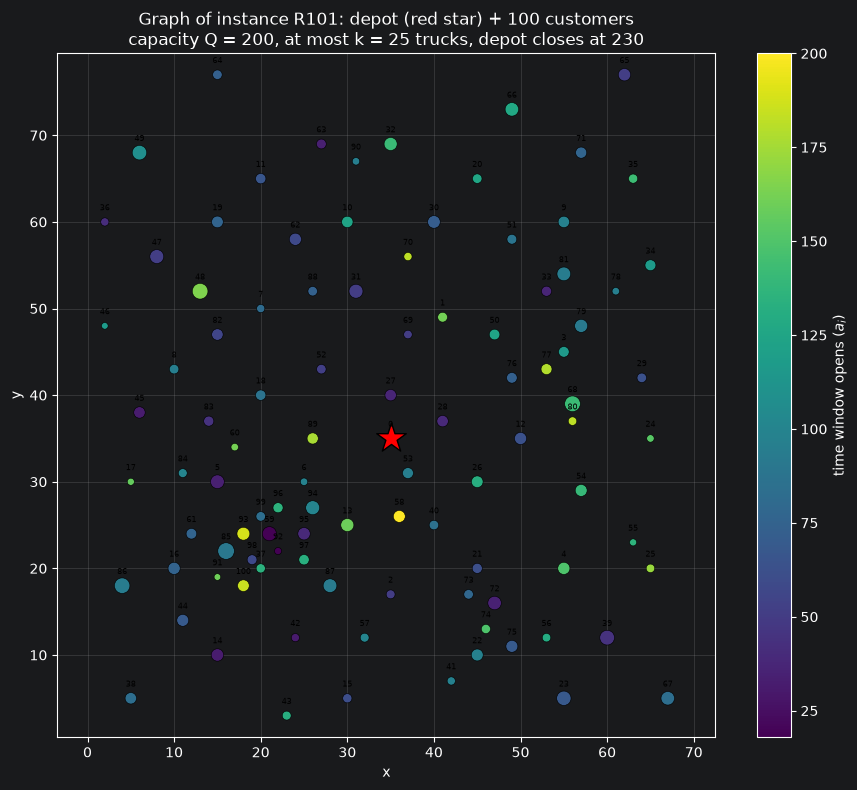

In [10]:
draw_instance(demo, path=f"{IMAGES_FOLDER}/{demo.name}_instance.png")

## 3.3 Run the ant colony
The colony prints its progress: the best distance found so far and the number of trucks it uses.

In [11]:
colony = AntColony(demo, LEVEL, seed=SEEDS[0], **ACO_SOLOMON)
print(f"Nearest-neighbour start: {len(colony.nn_routes)} trucks, distance {colony.nn_cost:.2f}")
demo_routes, demo_cost = colony.run()
print(f"\nBest solution: {len(demo_routes)} trucks, distance {demo_cost:.2f}, found in {colony.runtime:.1f} s")

Nearest-neighbour start: 21 trucks, distance 1969.01
  iteration   1 | best distance     1787.01 | trucks   22 |    0.2s
  iteration  10 | best distance     1704.35 | trucks   21 |    1.7s
  iteration  20 | best distance     1704.35 | trucks   21 |    3.4s
  iteration  30 | best distance     1704.35 | trucks   21 |    5.1s
  iteration  40 | best distance     1702.66 | trucks   21 |    6.8s
  iteration  50 | best distance     1702.66 | trucks   21 |    8.4s
  iteration  60 | best distance     1702.66 | trucks   21 |   10.1s
  iteration  70 | best distance     1702.66 | trucks   21 |   11.8s
  iteration  80 | best distance     1702.66 | trucks   21 |   13.5s

Best solution: 21 trucks, distance 1702.66, found in 13.5 s


## 3.4 The graph of the solution
One colour per truck; the arrows show the direction of each route, from the depot and back.

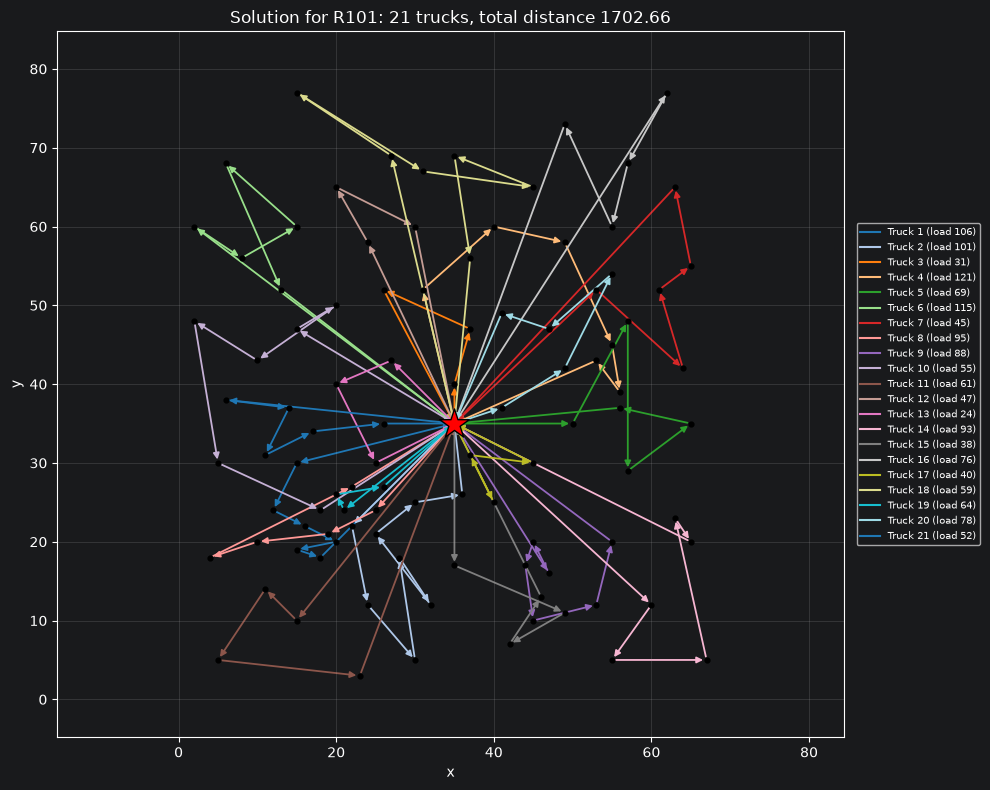

In [12]:
draw_solution(demo, demo_routes, path=f"{IMAGES_FOLDER}/{demo.name}_solution.png")

## 3.5 Check the solution and compute its gap
1. Every ILP constraint is tested.
2. Each truck's route and load are listed.
3. The gap to the best known solution is computed (section 6 explains the gap in detail).
4. The convergence curve shows how the best distance improved over the iterations.

ILP constraints:
  OK   (1) one road leaves each customer
  OK   (2) one road enters each customer
  OK   (3) trucks out = trucks in <= k
  OK   (4) load grows along each route
  OK   (5) d_i <= u_i <= Q
  OK   (9) x is binary
  OK   (6) clock grows along each route
  OK   (7) a_i <= t_i <= b_i
  OK   (8) back before the depot closes
All constraints satisfied: True 

Truck  1 | load  106/200 | 0 -> 5 -> 61 -> 85 -> 37 -> 91 -> 100 -> 0
Truck  2 | load  101/200 | 0 -> 92 -> 42 -> 15 -> 87 -> 57 -> 97 -> 13 -> 58 -> 0
Truck  3 | load   31/200 | 0 -> 27 -> 69 -> 88 -> 0
Truck  4 | load  121/200 | 0 -> 31 -> 30 -> 51 -> 3 -> 68 -> 77 -> 0
Truck  5 | load   69/200 | 0 -> 12 -> 79 -> 54 -> 24 -> 80 -> 0
Truck  6 | load  115/200 | 0 -> 36 -> 47 -> 19 -> 49 -> 48 -> 0
Truck  7 | load   45/200 | 0 -> 33 -> 29 -> 78 -> 34 -> 35 -> 0
Truck  8 | load   95/200 | 0 -> 95 -> 98 -> 16 -> 86 -> 96 -> 0
Truck  9 | load   88/200 | 0 -> 72 -> 21 -> 73 -> 22 -> 56 -> 4 -> 0
Truck 10 | load   55/200 | 0 -> 

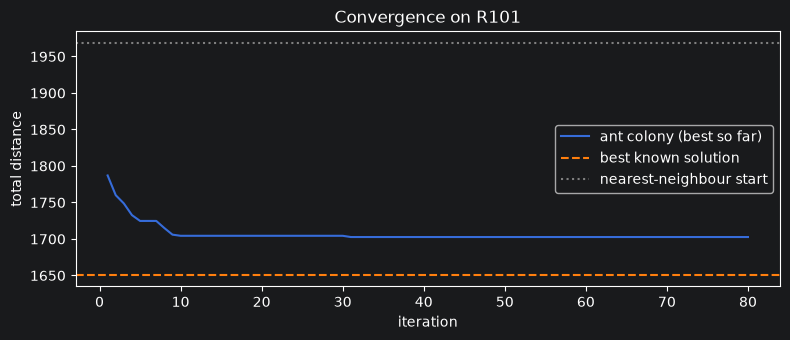

In [13]:
print("ILP constraints:")
ok, _ = check_ilp(demo, demo_routes, LEVEL)
print("All constraints satisfied:", ok, "\n")

for k, r in enumerate(demo_routes, 1):
    print(f"Truck {k:2d} | load {demo.d[r].sum():4.0f}/{demo.Q:.0f} | 0 -> " + " -> ".join(map(str, r)) + " -> 0")

bks_trucks, bks_dist = BKS[demo.name]
print(f"\nAnt colony : {len(demo_routes)} trucks, distance {demo_cost:.2f}")
print(f"Best known : {bks_trucks} trucks, distance {bks_dist:.2f}")
if LEVEL == "CVRPTW":
    print(f"Gap        : {100 * (demo_cost - bks_dist) / bks_dist:+.2f} % distance, {len(demo_routes) - bks_trucks:+d} trucks")
else:
    print("Gap        : not meaningful, the records are for the problem WITH time windows (LEVEL = 'CVRPTW')")

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, len(colony.history) + 1), colony.history, label="ant colony (best so far)")
plt.axhline(bks_dist, color="tab:orange", ls="--", label="best known solution")
plt.axhline(colony.nn_cost, color="grey", ls=":", label="nearest-neighbour start")
plt.xlabel("iteration"); plt.ylabel("total distance"); plt.title(f"Convergence on {demo.name}"); plt.legend()
plt.tight_layout(); plt.savefig(f"{IMAGES_FOLDER}/{demo.name}_convergence.png", dpi=150); plt.show()

---
# 4. Importing the instances
We import three datasets, each in its own section. Each import ends with a summary table, so you can check what was loaded before running anything.

| Dataset | Customers | Families | Best known solutions? |
|---|---|---|---|
| **Solomon** (1987) | 100 | C1, C2, R1, R2, RC1, RC2 (56 instances) | yes, for all 56 |
| **Gehring & Homberger** (1999) | 200, 400, 600, 800, 1000 | same six families, 10 instances each per size | yes, 200 to 800 |
| **NetworkX random graphs** | 499 to 9 999 (+ depot) | generated by this notebook | no, nobody has solved them |

**What the family names mean.** **C** = customers in clusters, **R** = customers spread at random, **RC** = a mix of both. **1** = short day and small trucks (many short routes), **2** = long day and big trucks (few long routes).

## 4.1 Solomon instances (100 customers)

In [14]:
solomon = {}
for name in SOLOMON_INSTANCES:
    inst = load_solomon(name, SOLOMON_FOLDER)
    if inst is not None:
        solomon[name] = inst

def summary_table(instances):
    return pd.DataFrame([{
        "Instance": name, "Family": family_of(name), "Customers": inst.n, "Trucks available (k)": inst.K,
        "Capacity (Q)": inst.Q, "Total demand": inst.d.sum(), "Depot closes (b0)": inst.b[0],
        "BKS trucks": BKS.get(name, (None, None))[0], "BKS distance": BKS.get(name, (None, None))[1],
    } for name, inst in instances.items()])

print(f"{len(solomon)} of {len(SOLOMON_INSTANCES)} Solomon instances imported")
summary_table(solomon)

56 of 56 Solomon instances imported


,Instance,Family,Customers,Trucks available (k),Capacity (Q),Total demand,Depot closes (b0),BKS trucks,BKS distance
0,C101,C1,100,25,200.0,1810.0,1236.0,10,828.94
1,C102,C1,100,25,200.0,1810.0,1236.0,10,828.94
2,C103,C1,100,25,200.0,1810.0,1236.0,10,828.06
3,C104,C1,100,25,200.0,1810.0,1236.0,10,824.78
4,C105,C1,100,25,200.0,1810.0,1236.0,10,828.94
5,C106,C1,100,25,200.0,1810.0,1236.0,10,828.94
6,C107,C1,100,25,200.0,1810.0,1236.0,10,828.94
7,C108,C1,100,25,200.0,1810.0,1236.0,10,828.94
8,C109,C1,100,25,200.0,1810.0,1236.0,10,828.94
9,C201,C2,100,25,700.0,1810.0,3390.0,3,591.56


## 4.2 Gehring & Homberger instances (200 to 1000 customers)
Instance names read `<family>_<size>_<number>`: `R1_4_3` is the 3rd R1 instance with **400** customers. The files are read from the `homberger/` folder (sub-folders are searched too); missing sizes are downloaded from SINTEF.

In [15]:
homberger = {}
for name in HOMBERGER_INSTANCES:
    inst = load_homberger(name, HOMBERGER_FOLDER)
    if inst is not None:
        homberger[name] = inst

print(f"{len(homberger)} of {len(HOMBERGER_INSTANCES)} Homberger instances imported")
summary_table(homberger)

  done: 60 files saved in ./homberger/
  done: 60 files saved in ./homberger/
  done: 60 files saved in ./homberger/
24 of 24 Homberger instances imported


,Instance,Family,Customers,Trucks available (k),Capacity (Q),Total demand,Depot closes (b0),BKS trucks,BKS distance
0,C1_2_1,C1,200,50,200.0,3530.0,1351.0,20,2704.57
1,C2_2_1,C2,200,50,700.0,3770.0,3598.0,6,1931.44
2,R1_2_1,R1,200,50,200.0,3513.0,634.0,20,4784.11
3,R2_2_1,R2,200,50,1000.0,3513.0,2535.0,4,4483.16
4,RC1_2_1,RC1,200,50,200.0,3558.0,634.0,18,3602.80
5,RC2_2_1,RC2,200,50,1000.0,3558.0,2535.0,6,3099.53
6,C1_4_1,C1,400,100,200.0,7190.0,1501.0,40,7152.02
7,C2_4_1,C2,400,100,700.0,7560.0,3693.0,12,4116.05
8,R1_4_1,R1,400,100,200.0,7109.0,804.0,40,10372.31
9,R2_4_1,R2,400,100,1000.0,7109.0,3213.0,8,9210.15


## 4.3 NetworkX random graphs (500 to 10 000 nodes)
For each size, NetworkX builds a graph with **1 depot + (N − 1) customers**:
- **nodes** carry the data: position, demand (10 to 40), time window, service time (10);
- **edges** link each node to its 15 nearest neighbours (the "road network" the ants mostly use);
- the map gets bigger with the number of nodes, so the density of customers stays the same as in Solomon;
- the random seed is fixed, so the same graphs are built every time.

There is no limit on the number of trucks for these graphs. The picture below shows the smallest graph with its edges.

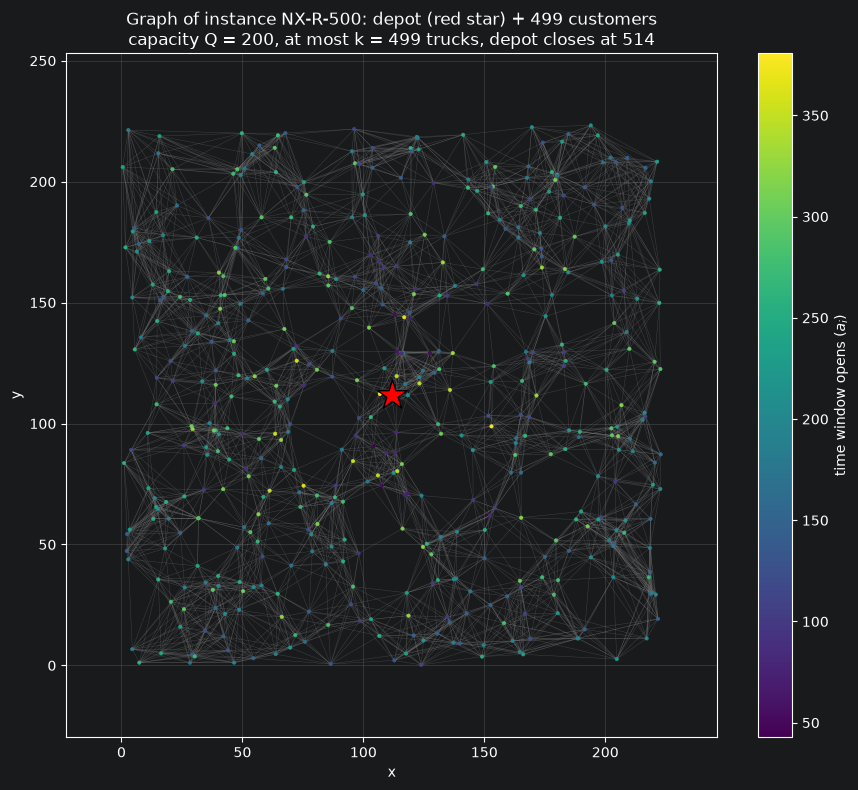

,Graph,Nodes,Customers,Edges,Connected,Map side,Capacity (Q),Total demand
0,NX-R-500,500,499,4298,True,223.4,200.0,12300.0
1,NX-R-1000,1000,999,8384,True,316.1,200.0,25080.0
2,NX-R-5000,5000,4999,42114,True,707.0,200.0,124740.0
3,NX-R-10000,10000,9999,83931,True,999.9,200.0,252290.0


In [16]:
nx_graphs, networkx_instances = {}, {}
for N in NX_SIZES:
    G = build_nx_graph(N, layout=NX_LAYOUT, Q=NX_CAPACITY)
    nx_graphs[G.graph["name"]] = G
    networkx_instances[G.graph["name"]] = instance_from_graph(G)

display_table = pd.DataFrame([{
    "Graph": name, "Nodes": G.number_of_nodes(), "Customers": G.number_of_nodes() - 1, "Edges": G.number_of_edges(),
    "Connected": nx.is_connected(G), "Map side": round(G.graph["side"], 1), "Capacity (Q)": G.graph["Q"],
    "Total demand": sum(nx.get_node_attributes(G, "demand").values()),
} for name, G in nx_graphs.items()])

smallest = min(networkx_instances, key=lambda k: networkx_instances[k].n)
draw_instance(networkx_instances[smallest], path=f"{IMAGES_FOLDER}/{smallest}_graph.png", show_edges_of=nx_graphs[smallest])
display_table

---
# 5. Running the Ant Colony Algorithm
The helper below runs the colony on a set of instances, once per seed, and records for each run:
- the number of trucks and the total distance found,
- whether **all ILP constraints** are satisfied,
- the nearest-neighbour distance (the simple baseline),
- the run time and the convergence curve.

Results are **saved after every run** in `results/`. If you stop a long run and start it again with the same settings, finished runs are read back from the file instead of being recomputed.

In [17]:
HISTORIES = {}      # convergence curves: (instance, seed) -> list of best distances
SOLUTIONS = {}      # routes found:       (instance, seed) -> list of routes


def run_dataset(instances, settings, csv_name):
    path = os.path.join(RESULTS_FOLDER, csv_name)
    signature = json.dumps({"level": LEVEL, **settings}, sort_keys=True)   # identifies the settings used
    rows = pd.read_csv(path).to_dict("records") if os.path.exists(path) else []
    done = {(r["Instance"], r["Seed"], r["Settings"]) for r in rows}
    todo = [(name, seed) for name in instances for seed in SEEDS if (name, seed, signature) not in done]
    print(f"{len(todo)} runs to do, {len(instances) * len(SEEDS) - len(todo)} already saved in {path}")

    t_start = time.time()
    for k, (name, seed) in enumerate(todo, 1):
        inst = instances[name]
        colony = AntColony(inst, LEVEL, seed=seed, **settings)
        routes, cost = colony.run(verbose=False)
        ok = check_ilp(inst, routes, LEVEL, verbose=False)[0] if routes else False
        rows.append({"Instance": name, "Family": family_of(name), "Customers": inst.n, "Seed": seed,
                     "Trucks": len(routes) if routes else None, "Distance": round(cost, 2) if routes else None,
                     "Feasible": ok, "NN trucks": len(colony.nn_routes) if colony.nn_routes else None,
                     "NN distance": round(colony.nn_cost, 2), "Iterations done": len(colony.history),
                     "Time (s)": round(colony.runtime, 1), "Settings": signature})
        HISTORIES[(name, seed)], SOLUTIONS[(name, seed)] = list(colony.history), routes
        pd.DataFrame(rows).to_csv(path, index=False)
        print(f"[{k}/{len(todo)}] {name:10s} seed {seed}: {rows[-1]['Trucks']} trucks, distance {rows[-1]['Distance']}, "
              f"feasible={ok}, {colony.runtime:.1f}s  (total {time.time() - t_start:.0f}s)")

    df = pd.DataFrame(rows)
    return df[(df["Settings"] == signature) & df["Instance"].isin(list(instances)) & df["Seed"].isin(SEEDS)].reset_index(drop=True)

## 5.1 Solomon

In [ ]:
solomon_results = run_dataset(solomon, ACO_SOLOMON, "solomon_results.csv")
solomon_results.drop(columns="Settings")

168 runs to do, 0 already saved in results\solomon_results.csv
[1/168] C101       seed 1: 10 trucks, distance 828.94, feasible=True, 26.2s  (total 26s)
[2/168] C101       seed 2: 10 trucks, distance 828.94, feasible=True, 26.2s  (total 52s)
[3/168] C101       seed 3: 10 trucks, distance 828.94, feasible=True, 26.4s  (total 79s)
[4/168] C102       seed 1: 11 trucks, distance 937.62, feasible=True, 28.3s  (total 107s)
[5/168] C102       seed 2: 10 trucks, distance 893.46, feasible=True, 28.2s  (total 135s)
[6/168] C102       seed 3: 10 trucks, distance 876.9, feasible=True, 28.2s  (total 164s)
[7/168] C103       seed 1: 11 trucks, distance 936.01, feasible=True, 28.7s  (total 192s)
[8/168] C103       seed 2: 10 trucks, distance 976.53, feasible=True, 28.8s  (total 221s)
[9/168] C103       seed 3: 10 trucks, distance 942.17, feasible=True, 28.7s  (total 250s)
[10/168] C104       seed 1: 10 trucks, distance 887.96, feasible=True, 29.2s  (total 279s)
[11/168] C104       seed 2: 10 trucks, d

## 5.2 Gehring & Homberger

In [ ]:
homberger_results = run_dataset(homberger, ACO_HOMBERGER, "homberger_results.csv")
homberger_results.drop(columns="Settings")

## 5.3 NetworkX graphs
The biggest graph (10 000 nodes) takes about 12 seconds per iteration. The solution of the 1 000-node graph is drawn at the end (when it was solved in this session; runs read back from the saved file have no routes to draw).

In [ ]:
networkx_results = run_dataset(networkx_instances, ACO_NETWORKX, "networkx_results.csv")

example = next((k for k in networkx_instances if networkx_instances[k].n == 999), smallest)
if (example, SEEDS[0]) in SOLUTIONS:
    draw_solution(networkx_instances[example], SOLUTIONS[(example, SEEDS[0])], path=f"{IMAGES_FOLDER}/{example}_solution.png")
networkx_results.drop(columns="Settings")

---
# 6. Calculating the gap
The **gap** says how far our result is from the best known solution (BKS), the best result ever published for that instance:

$$\text{gap}\;(\%) = 100 \times \frac{\text{our distance} - \text{BKS distance}}{\text{BKS distance}}$$

A gap of 0 % means we matched the record; 5 % means our trucks drive 5 % more than the record.

**Always read the gap together with the number of trucks.** The records were found with a different rule: **first use as few trucks as possible, then minimise distance**. Our ILP only minimises distance (with at most $k$ trucks). So:
- we sometimes use **more trucks** than the record (column *Extra trucks*);
- with more trucks, the distance can even be **shorter** than the record, which gives a **negative gap**. That is not a better solution under the record's rule, just a different trade-off.

**NetworkX graphs have no record**, so we cannot compute a gap for them. Instead we report the **improvement over the nearest-neighbour solution** (how much shorter our routes are than "always drive to the closest possible customer"). This shows that the colony improves on a simple method, but not how far it is from the best possible solution.

When several seeds are used, each instance's result is the **average over its seeds**.

In [ ]:
def add_gaps(df):
    df = df.copy()
    df["BKS trucks"] = [BKS.get(n, (None, None))[0] for n in df["Instance"]]
    df["BKS distance"] = [BKS.get(n, (None, None))[1] for n in df["Instance"]]
    valid = (LEVEL == "CVRPTW")                       # the records are for the problem with time windows
    df["Gap %"] = (100 * (df["Distance"] - df["BKS distance"]) / df["BKS distance"]) if valid else np.nan
    df["Extra trucks"] = (df["Trucks"] - df["BKS trucks"]) if valid else np.nan
    df["Extra trucks %"] = (100 * df["Extra trucks"] / df["BKS trucks"]) if valid else np.nan
    return df


def per_instance(df):
    # one row per instance: average over the seeds
    g = df.groupby("Instance", sort=False)
    return pd.DataFrame({
        "Family": g["Family"].first(), "Customers": g["Customers"].first(), "Seeds": g["Seed"].count(),
        "Trucks": g["Trucks"].mean(), "BKS trucks": g["BKS trucks"].first(),
        "Distance": g["Distance"].mean(), "BKS distance": g["BKS distance"].first(),
        "Gap %": g["Gap %"].mean(), "Gap % (best seed)": g["Gap %"].min(),
        "Extra trucks": g["Extra trucks"].mean(), "Extra trucks %": g["Extra trucks %"].mean(),
        "All feasible": g["Feasible"].all(), "Time (s)": g["Time (s)"].mean(),
    }).round(2).reset_index()


def family_table(inst_df, by=("Family",)):
    g = inst_df.groupby(list(by))
    return pd.DataFrame({
        "Instances": g["Instance"].count(),
        "Mean gap %": g["Gap %"].mean(), "Best gap %": g["Gap %"].min(), "Worst gap %": g["Gap %"].max(),
        "Gap < 1 %": g["Gap %"].apply(lambda v: int((v < 1).sum())), "Gap < 5 %": g["Gap %"].apply(lambda v: int((v < 5).sum())),
        "Mean extra trucks": g["Extra trucks"].mean(), "All feasible": g["All feasible"].all(),
    }).round(2)

FAMILY_COLOURS = {f: plt.get_cmap("tab10")(i) for i, f in enumerate(["C1", "C2", "R1", "R2", "RC1", "RC2"])}
print("Gap helpers ready.")

## 6.1 Solomon gaps
First the gap of every instance, then a summary per family, then the charts:
- **left:** the gap of every instance, coloured by family;
- **middle:** the spread of the gap inside each family (box = middle half of the instances, line = median);
- **right:** the average number of extra trucks per family.

In [ ]:
solomon_gaps = per_instance(add_gaps(solomon_results))
solomon_gaps.to_csv(f"{RESULTS_FOLDER}/solomon_gaps.csv", index=False)
display(solomon_gaps)
family_table(solomon_gaps)

In [ ]:
def plot_family_gaps(gaps, title, path):
    fams = [f for f in FAMILY_COLOURS if f in set(gaps["Family"])]
    fig, ax = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={"width_ratios": [2.2, 1, 1]})
    ax[0].bar(range(len(gaps)), gaps["Gap %"], color=[FAMILY_COLOURS[f] for f in gaps["Family"]])
    ax[0].set_xticks(range(len(gaps))); ax[0].set_xticklabels(gaps["Instance"], rotation=90, fontsize=7)
    ax[0].axhline(0, color="k", lw=0.8); ax[0].set_ylabel("gap (%)"); ax[0].set_title(f"{title}: gap of every instance")
    ax[0].legend(handles=[Line2D([], [], color=FAMILY_COLOURS[f], lw=6, label=f) for f in fams], ncol=6, fontsize=8)
    data = [gaps[gaps["Family"] == f]["Gap %"].dropna().values for f in fams]
    ax[1].boxplot(data, positions=range(1, len(fams) + 1), widths=0.55)
    ax[1].set_xticks(range(1, len(fams) + 1)); ax[1].set_xticklabels(fams)
    ax[1].axhline(0, color="k", lw=0.8); ax[1].set_ylabel("gap (%)"); ax[1].set_title("Gap by family")
    extra = [gaps[gaps["Family"] == f]["Extra trucks"].mean() for f in fams]
    ax[2].bar(fams, extra, color=[FAMILY_COLOURS[f] for f in fams])
    ax[2].axhline(0, color="k", lw=0.8); ax[2].set_ylabel("trucks"); ax[2].set_title("Average extra trucks vs record")
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

plot_family_gaps(solomon_gaps, "Solomon", f"{IMAGES_FOLDER}/solomon_gaps.png")

## 6.2 Gehring & Homberger gaps
The same tables, then one more question: **does the gap change with the number of customers?**
- **left:** average gap per family for each size;
- **middle:** spread of the gap for each size (all families together);
- **right:** extra trucks, in % of the record's trucks, per family and size.

In [ ]:
homberger_gaps = per_instance(add_gaps(homberger_results))
homberger_gaps.to_csv(f"{RESULTS_FOLDER}/homberger_gaps.csv", index=False)
display(homberger_gaps)
print("Mean gap (%) per family (rows) and number of customers (columns):")
homberger_gaps.pivot_table(index="Family", columns="Customers", values="Gap %", aggfunc="mean").round(2)

In [ ]:
def plot_gap_vs_size(gaps, title, path):
    sizes = sorted(gaps["Customers"].unique())
    fams = [f for f in FAMILY_COLOURS if f in set(gaps["Family"])]
    fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
    for f in fams:
        sub = gaps[gaps["Family"] == f].groupby("Customers")
        ax[0].plot(sub["Gap %"].mean(), "o-", color=FAMILY_COLOURS[f], label=f)
        ax[2].plot(sub["Extra trucks %"].mean(), "o-", color=FAMILY_COLOURS[f], label=f)
    data = [gaps[gaps["Customers"] == s]["Gap %"].dropna().values for s in sizes]
    ax[1].boxplot(data, positions=range(1, len(sizes) + 1), widths=0.55)
    ax[1].set_xticks(range(1, len(sizes) + 1)); ax[1].set_xticklabels([str(int(s)) for s in sizes])
    for a_, ylab, t in ((ax[0], "gap (%)", "Average gap per family"), (ax[1], "gap (%)", "Spread of the gap by size"),
                        (ax[2], "extra trucks (% of record)", "Extra trucks per family")):
        a_.axhline(0, color="k", lw=0.8); a_.set_xlabel("customers"); a_.set_ylabel(ylab); a_.set_title(f"{title}: {t}")
    for a_ in (ax[0], ax[2]):
        a_.set_xticks(sizes); a_.legend(fontsize=8, ncol=2)
    plt.tight_layout(); plt.savefig(path, dpi=150); plt.show()

display(family_table(homberger_gaps))
plot_gap_vs_size(homberger_gaps, "Homberger", f"{IMAGES_FOLDER}/homberger_gaps.png")

## 6.3 NetworkX graphs: improvement over the nearest-neighbour solution
No record exists for these graphs, so the table shows how much shorter the colony's routes are than the nearest-neighbour routes, plus the run time per iteration. The charts show:
- **left:** improvement over nearest neighbour for each size;
- **middle:** time per iteration against the number of nodes (log scales: a straight line of slope 1 means the time grows in proportion to the size);
- **right:** convergence, as best distance divided by the nearest-neighbour distance (available for the runs made in this session).

*Careful when comparing sizes:* the map grows with the number of nodes, so on big graphs most of the distance is the unavoidable drive between the depot and each truck's area. Even a perfect algorithm would show a smaller improvement there.

In [ ]:
g = networkx_results.groupby("Instance", sort=False)
networkx_summary = pd.DataFrame({
    "Nodes": g["Customers"].first() + 1, "Seeds": g["Seed"].count(),
    "NN trucks": g["NN trucks"].mean(), "NN distance": g["NN distance"].mean(),
    "Trucks": g["Trucks"].mean(), "Distance": g["Distance"].mean(),
    "Improvement vs NN %": 100 * (g["NN distance"].mean() - g["Distance"].mean()) / g["NN distance"].mean(),
    "All feasible": g["Feasible"].all(), "Time (s)": g["Time (s)"].mean(),
    "Time per iteration (s)": g["Time (s)"].mean() / g["Iterations done"].mean(),
}).round(2).reset_index().rename(columns={"Instance": "Graph"})
networkx_summary.to_csv(f"{RESULTS_FOLDER}/networkx_summary.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
ax[0].bar(networkx_summary["Nodes"].astype(str), networkx_summary["Improvement vs NN %"], color="#27ae60")
ax[0].set_xlabel("nodes"); ax[0].set_ylabel("%"); ax[0].set_title("Improvement over nearest neighbour")
ax[1].loglog(networkx_summary["Nodes"], networkx_summary["Time per iteration (s)"], "o-")
for x_, y_ in zip(networkx_summary["Nodes"], networkx_summary["Time per iteration (s)"]):
    ax[1].annotate(f"{y_:.2f}s", (x_, y_), textcoords="offset points", xytext=(5, -12), fontsize=8)
ax[1].set_xlabel("nodes"); ax[1].set_ylabel("seconds per iteration"); ax[1].set_title("Run time per iteration")
for name in networkx_summary["Graph"]:
    for seed in SEEDS:
        if (name, seed) in HISTORIES:
            nn = networkx_results[(networkx_results["Instance"] == name) & (networkx_results["Seed"] == seed)]["NN distance"].iloc[0]
            ax[2].plot(np.array(HISTORIES[(name, seed)]) / nn, label=f"{name} (seed {seed})")
ax[2].set_xlabel("iteration"); ax[2].set_ylabel("best / nearest-neighbour distance"); ax[2].set_title("Convergence")
if ax[2].lines: ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{IMAGES_FOLDER}/networkx_results.png", dpi=150); plt.show()
networkx_summary

## 6.4 Overall: the gap as the number of customers grows
Solomon (100 customers) and Homberger (200 to 800) put together, for the instances that have a record:
- **left:** spread of the gap for each size;
- **right:** average gap per family for each size.

The table gives the same numbers: average, best and worst gap per size, and the average number of extra trucks.

In [ ]:
parts = [df for df in (globals().get("solomon_gaps"), globals().get("homberger_gaps")) if df is not None]
all_gaps = pd.concat(parts, ignore_index=True).dropna(subset=["Gap %"])
sizes = sorted(all_gaps["Customers"].unique())

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
ax[0].boxplot([all_gaps[all_gaps["Customers"] == s]["Gap %"].values for s in sizes],
              positions=range(1, len(sizes) + 1), widths=0.55)
ax[0].set_xticks(range(1, len(sizes) + 1)); ax[0].set_xticklabels([str(int(s)) for s in sizes])
ax[0].set_title("Spread of the gap by number of customers")
for f in [f for f in FAMILY_COLOURS if f in set(all_gaps["Family"])]:
    m = all_gaps[all_gaps["Family"] == f].groupby("Customers")["Gap %"].mean()
    ax[1].plot(m.index, m.values, "o-", color=FAMILY_COLOURS[f], label=f)
ax[1].set_xticks(sizes); ax[1].legend(ncol=2, fontsize=8); ax[1].set_title("Average gap per family")
for a_ in ax:
    a_.axhline(0, color="k", lw=0.8); a_.set_xlabel("customers"); a_.set_ylabel("gap (%)")
plt.tight_layout(); plt.savefig(f"{IMAGES_FOLDER}/gap_vs_size.png", dpi=150); plt.show()

g = all_gaps.groupby("Customers")
pd.DataFrame({"Instances": g["Instance"].count(), "Mean gap %": g["Gap %"].mean(), "Best gap %": g["Gap %"].min(),
              "Worst gap %": g["Gap %"].max(), "Mean extra trucks": g["Extra trucks"].mean(),
              "Mean extra trucks %": g["Extra trucks %"].mean(), "All feasible": g["All feasible"].all()}).round(2)

---
# 7. Reading the results
**What to look at, in this order:**
1. **Feasibility.** Every *All feasible* value should be `True`: the colony's routes satisfy every constraint of the ILP.
2. **Gap by family (6.1 and 6.2).** Compare clustered (C), random (R) and mixed (RC) customers, and short-route (1) against long-route (2) families. The family usually matters more than anything else.
3. **Extra trucks.** A small or negative gap obtained with many extra trucks is a different trade-off, not a better solution under the record's rule.
4. **Gap against size (6.4).** Does the average gap grow from 100 to 800 customers, and for which families?
5. **NetworkX graphs (6.3).** The run time per iteration shows how the method scales; the improvement over nearest neighbour shows whether the colony still learns on very large graphs (watch for flat convergence curves).

**Be careful with:**
- **One seed is one sample.** With `SEEDS = [1]`, a difference of one or two percent between two instances can be chance. Use `SEEDS = [1, 2, 3]` for results you want to present.
- **Different objectives.** The records minimise trucks first; our ILP minimises distance. State this whenever you show a gap.
- **No gap for NetworkX.** Call it "improvement over a simple baseline", never "gap".
- **CVRP level.** With `LEVEL = "CVRP"`, gaps are not computed, because the records are for the problem with time windows.

**Ways to improve the colony:** more iterations for small instances; more clean-up passes (`LS_PASSES`) and a longer shortlist (`N_CANDIDATES`) for large ones; a penalty per truck to follow the records' rule; and splitting very large maps into zones solved separately.